## Karpathy Video 2 on makemore
- read the Bengio paper
- problem = combinatoric explosion as we increase the number of letters...(27, 27x27, 27x27x27, ...)
- each word is embedded into a 30 dimension *feature vector* (aka embedding, aka encoding)
- we will **tune** the embeddings with back propagation

C is a lookup table : shape(17000, 30)

that maps word index 0..17000 --> 30 dim embedding (randomly weighted to start?)

a **hyper-parameter** is a value that we **tune** to see which works best 
    - e.g. the number of tanh nodes in the first hidden layer of what we are building

in training we have the label of the next word - and we maximize the probabilty of that word wrt the parameters

the output of the NN is the probability of the next word

the parameters are the weights and biases of the tanh and the 1700 logit layer AND the lookup table C (the embeddings)


## Bengio's Neural Probabilistic Language Model (NPLM)

Three layers: 

1. a lookup-table embedding

2. one fully-connected `tanh` hidden layer

3. a softmax output over the vocabulary.

```text
context words (indices)
   w1   w2   w3
    |    |    |
    v    v    v
 +------------------+
 |  Embedding Table |   C[vocab_size, 30]  -- shared across all context positions
 +------------------+
    |    |    |
    v    v    v
  [30]  [30]  [30]        each word -> its own 30-dim embedding vector
    \    |    /
     \   |   /
      concatenate                          -> one [C * 30] vector
          |
          v
 +----------------------+
 |  Hidden Layer (tanh) |   W1[C*30, n_hidden], b1[n_hidden]
 +----------------------+
          |
          v
      [n_hidden]                            -- tanh-activated
          |
          v
 +----------------------+
 |   Output Layer       |   W2[n_hidden, 17000], b2[17000]
 |   (logits)           |
 +----------------------+
          |
          v
     [17000] logits
          |
          v
       softmax
          |
          v
  probability distribution
   over the 17,000-word
        vocabulary
```

**Layer by layer:**

1. **Embedding lookup** — each context word index is used to select a row
   from a shared `[vocab_size, 30]` embedding table `C`, producing a 30-dim
   vector per word. This table is a learned parameter, not fixed — see
   [[one-hot-encoding]]: this lookup is mathematically `onehot(word) @ C`.

2. **Concatenate** — if the model conditions on more than one previous word
   (context size `C`), the per-word embeddings are concatenated into a single
   vector of size `C * 30` before the hidden layer. (With a single context
   word, this is just the 30-dim vector, unconcatenated.)

3. **Hidden layer** — one fully-connected layer, `tanh` activation:
   `h = tanh(concat_embeddings @ W1 + b1)`.

4. **Output layer** — a fully-connected layer producing 17,000 logits (one
   per vocabulary word): `logits = h @ W2 + b2`.

5. **Softmax** — turns the 17,000 logits into a probability distribution
   over the next word — see [[softmax]]. Trained with negative log-likelihood
   against the true next word — see [[nll-vs-mse]].

Two notes on the numbers, since they're specific to the original paper (and Karpathy's makemore walkthrough of it):

  - 17,000 is the vocabulary size from Bengio et al. 2003 (Associated Press News corpus, ~17,964 unique words) — swap it for whatever your own vocab size is if this is going
    into your makemore notes rather than a description of the original paper.
  - I generalized to context size C (concatenating multiple context words' embeddings) since that's how the actual NPLM works — it predicts the next word from several
  preceding words, not just one. If you specifically mean a single-word context, drop the "concatenate" step and just feed the 30-dim vector straight into the hidden layer.

```mermaid
flowchart TD
    W1["context word 1"] --> Emb1["Embedding lookup<br/>C (vocab_size, 30)"]
    W2["context word 2"] --> Emb2["Embedding lookup<br/>C (vocab_size, 30)"]
    W3["context word 3"] --> Emb3["Embedding lookup<br/>C (vocab_size, 30)"]

    Emb1 --> V1["30-dim vector"]
    Emb2 --> V2["30-dim vector"]
    Emb3 --> V3["30-dim vector"]

    V1 --> Cat["Concatenate<br/>C * 30 dims"]
    V2 --> Cat
    V3 --> Cat

    Cat --> Hidden["Hidden layer tanh<br/>h = tanh(x @ W1 + b1)<br/>n_hidden dims"]
    Hidden --> Out["Output layer logits<br/>logits = h @ W2 + b2<br/>17000 dims"]
    Out --> Soft["Softmax"]
    Soft --> Prob["Probability distribution<br/>over 17,000-word vocabulary"]
```

In [1]:

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
%matplotlib inline


In [58]:
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [78]:
len(words)

32033

In [59]:
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [60]:
# build the dataset

# takes the name and shows each 3 char context and the next predicted char

block_size = 3 #context length:  how many chars do we need to predict the next one?
X, Y = [], [] # X are the input, Y are the labels for each example inside X
for w in words:

    # print(w)
    context = [0] * block_size
    for ch in w + '.':
        ix = stoi[ch]
        X.append(context)
        Y.append(ix)
        # print(''.join(itos[i] for i in context), '--->', itos[ix])
        context = context[1:] + [ix] # crop and append

X = torch.tensor(X)
Y = torch.tensor(Y)


In [5]:
Y.shape, X.shape


(torch.Size([228146]), torch.Size([228146, 3]))

In [35]:
Y # the labels

tensor([ 5, 13, 13,  ..., 26, 24,  0])

In [84]:
# we are going to use a 2 dim embedding space
C = torch.randn((27, 2), requires_grad=True)
C

tensor([[ 1.0741,  0.0641],
        [ 0.6181,  0.5105],
        [-0.1468, -1.9899],
        [-2.1270,  0.3196],
        [ 2.7391,  0.3411],
        [ 0.0956,  0.0469],
        [ 1.1732,  1.0908],
        [-0.4827, -0.5778],
        [-0.6452,  0.4914],
        [ 1.0054, -1.4520],
        [-0.5121, -1.5406],
        [-0.3879,  0.8337],
        [-1.4353, -0.6799],
        [ 1.3163, -0.6887],
        [ 0.2150, -2.5160],
        [-2.7263, -0.9427],
        [ 0.4774,  0.4612],
        [-0.0062, -0.9339],
        [-1.1597,  0.3739],
        [ 1.7108, -0.9698],
        [-1.7434, -1.2883],
        [-1.4087,  0.1578],
        [-0.3018, -0.9510],
        [-0.4900,  0.6071],
        [-0.9883, -0.7662],
        [ 1.0664,  0.2364],
        [-1.0301,  1.2179]], requires_grad=True)

In [37]:
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

tensor([0.1102, 1.2167], grad_fn=<SqueezeBackward4>)

In [38]:
C[5]

tensor([0.1102, 1.2167], grad_fn=<SelectBackward0>)

# Coool

```
F.one_hot(torch.tensor(5), num_classes=27).float() @ C

is equivalent to 

C[5]
```

we're going to us the index
😎

In [39]:
C[torch.tensor([5, 6, 7, 7, 7])] # index with a list or a tensor..

tensor([[ 0.1102,  1.2167],
        [ 1.6689,  0.4765],
        [ 0.5060, -0.5628],
        [ 0.5060, -0.5628],
        [ 0.5060, -0.5628]], grad_fn=<IndexBackward0>)

In [40]:
# can also index with multi dimensional tensors

C[X].shape

torch.Size([228146, 3, 2])

In [41]:
emb = C[X]
emb.shape

torch.Size([228146, 3, 2])

In [61]:
W1 = torch.randn((6, 100), requires_grad=True)
b1 = torch.randn(100, requires_grad=True)

In [43]:
# we want something like emb @ W1  + b1
# but the shapes wont matmul.. (32, 3, 2) @ (6, 100)
# we need to concatenate somehow

torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape

# generalizes to : (so we can change the context)

# torch.cat(torch.unbind(emb, 1), 1).shape. inefficient with memory

torch.Size([228146, 6])

In [ ]:
# but there is a better way!
# .view vs .reshape - use reshape as a default, 
# use .view for strict high performance code with contiguous memory

print(emb.shape) 
print(emb.view(32, 6).shape) # <----- like dis
print("@")
print(W1.shape, "+", b1.shape)

# h = emb.view(32, 6)

# the -1 will have pytorch infer the dimension

h = torch.tanh(emb.view(-1, 6) @ W1 + b1)


In [62]:
W2 = torch.randn((100, 27), requires_grad=True)
b2 = torch.randn(27, requires_grad=True)

In [84]:
logits = h @ W2 + b2
logits.shape

torch.Size([32, 27])

In [47]:
logits.shape

torch.Size([32, 27])

In [48]:
counts = logits.exp()

In [85]:
prob = counts / counts.sum(dim=1, keepdim=True)

In [50]:
prob.shape

torch.Size([32, 27])

In [ ]:
loss = prob[torch.arange(32), Y].log().mean()
loss

In [52]:
# now made respectable..

In [124]:
g = torch.Generator().manual_seed(2147483647)
C = torch.randn((27, 10), generator=g) # changed embedding space from 2 to 
W1 = torch.randn((30, 200), generator=g) # changed from 100 to 300, then down to 200
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

In [125]:
sum(p.nelement() for p in parameters)

11897

In [ ]:
## this is the cross-entropy! ##
#
# counts = logits.exp()
# probs = counts / counts.sum(1, keepdim=True) # sums are in a column
# loss = -prob[torch.arange(32), Y].log().mean()
#
## and is in the function here :  ##

loss = F.cross_entropy(logits, Y) # type: ignore

In [13]:
# finding a good learning rate:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [ ]:
lri = []
lossi = []

# not final version.. scroll down 

# not final version.. scroll down 

# not final version.. scroll down 

# not final version.. scroll down 

# not final version.. scroll down 

# not final version.. scroll down 

for i in range(3000):

    # minibatch construct
    # much better to have an approximate gradient and take more more steps thantit is
    # to take the exact gradient and take fewer steps
    ix = torch.randint(0, X.shape[0], (32,))

    # forward pass
    emb = C[X[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
    logits = h @ W2 + b2 # (32, 27)
    loss = F.cross_entropy(logits, Y[ix]) # type: ignore
    print(loss.item())
    
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    lr = lrs[i]
    for p in parameters:
        p.data += -0.1 * p.grad

    # track stats

    lri.append(lr)
    lossi.append(loss.item())
    

In [ ]:
plt.plot(lri, lossi)

### with large data sets we want to train on a mini-batch

 - much better to have an approximate gradient and take more steps than it is to take the exact gradient and take fewer steps

In [60]:
torch.randint(0, X.shape[0], (32,))

tensor([ 32138,  28583, 216405, 217258,  38203, 123199, 162645,  76864,  50005,
         50877, 197720, 152233, 197079, 220676, 158890,  99205, 214484, 122271,
        194274, 172940,  92041,  93564, 112420,  10451, 217740, 104635,  44816,
         96556, 202225,  50659, 103489,  33312])

In [61]:
emb = C[X] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Y) # type: ignore
loss

tensor(2.4103, grad_fn=<NllLossBackward0>)

In [16]:
import random 

# Splitting the data set into train, dev and test

In [ ]:
# 3 data splits - training / dev, validation split / test split
# 80% (gradient descent - optimize model) / 10% (hyperparameter tuning) / 10% (final evaluation)

# lets make a function to split the data sets : 


def build_dataset(words):
    block_size = 3 #context length:  how many chars do we need to predict the next one?
    X, Y = [], [] # X are the input, Y are the labels for each example inside X
    for w in words:

        # print(w)
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            # print(''.join(itos[i] for i in context), '--->', itos[ix])
            context = context[1:] + [ix] # crop and append

    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y


random.seed(42)
random.shuffle(words)

n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))

# our 3 splits : 
# approximately 80/10/10 is a good rule of thumb

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

print(Xtr.shape, Ytr.shape)
print(Xdev.shape, Ydev.shape)
print(Xte.shape, Yte.shape)


torch.Size([182512, 3]) torch.Size([182512])
torch.Size([22860, 3]) torch.Size([22860])
torch.Size([22774, 3]) torch.Size([22774])


In [127]:
lri = []
lossi = []
stepi = []


In [128]:

for i in range(200000):

    # minibatch construct
    # much better to have an approximate gradient and take more more steps thantit is
    # to take the exact gradient and take fewer steps
    ix = torch.randint(0, Xtr.shape[0], (32,))

    # forward pass
    emb = C[Xtr[ix]] # (32, 3, 2)
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
    logits = h @ W2 + b2 # (32, 27)
    loss = F.cross_entropy(logits, Ytr[ix]) # type: ignore
    # print(loss.item())
    
    # backward pass
    for p in parameters:
        p.grad = None
    loss.backward()

    # update
    # lr = lrs[i]
    # Each parameter gets updated by the gradient times the learning rate.  
    # This is the step of gradient descent.
    lr = 0.1 if i < 100000 else 0.01 # some LR decay after 100k steps
    for p in parameters:
        p.data += -lr * p.grad

    # track stats

    # lri.append(lr)
    stepi.append(i)
    lossi.append(loss.log10().item())
    
    

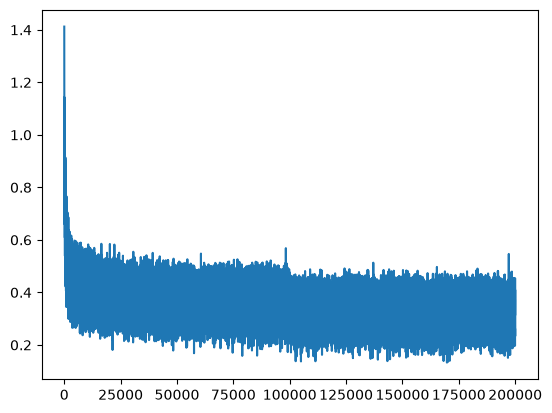

In [129]:
# the loss functoin and how it's being optimized.
plt.plot(stepi, lossi)


In [130]:
print(loss.item())

1.813341498374939


In [131]:
# Validation

emb = C[Xdev] # (32, 3, 2)
h = torch.tanh(emb.view(-1, 30) @ W1 + b1) # (32, 100)
logits = h @ W2 + b2 # (32, 27)
loss = F.cross_entropy(logits, Ydev) # type: ignore
print(loss.item())  

2.1768901348114014


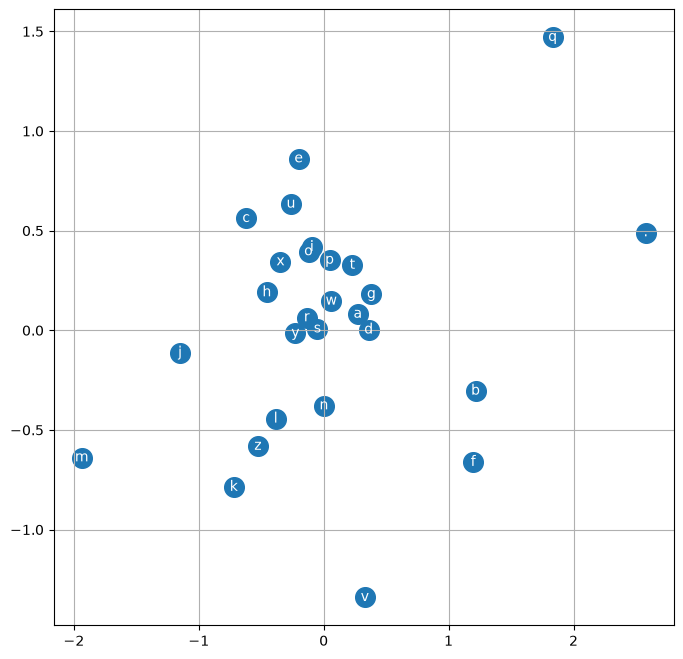

In [132]:
plt.figure(figsize=(8, 8))
plt.scatter(C[:, 0].data, C[:, 1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i, 0].item(), C[i, 1].item(), itos[i], ha='center', va='center', color='white')

plt.grid('minor')

## Experiments in Model Training

In productions you would run lots of **experiments** with **different hyper parameters** to see what worked best!

# Here's how we can Sample the data from our model..

In [134]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    out = []
    context = [0] * block_size # block size is 3
    while True:
        emb = C[torch.tensor([context])] # (1, block_size, d)
        h = torch.tanh(emb.view(1, -1) @ W1 + b1) # 
        logits = h @ W2 + b2 # (1, 27)
        counts = logits.exp()
        prob = F.softmax(logits, dim=1) # (1, 27)
        ix = torch.multinomial(prob, num_samples=1, generator=g).item()
        context = context[1:] + [ix]
        out.append(ix)
        if ix == 0:
            break
    print(''.join(itos[i] for i in out))


carmah.
amilli.
khi.
mili.
taty.
hacey.
kenlehutn.
deliah.
jareen.
nellari.
chaiir.
kaleigh.
ham.
porriquinn.
shonne.
liveni.
wazell.
dearisi.
jaxen.
dura.
